In [27]:
from sklearn.datasets import make_classification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

In [6]:
n = 1000
x = np.linspace(-3,3,n)
y = x**2 + np.random.random(n)*0.5

In [9]:
model = LinearRegression()
model.fit(x.reshape(-1,1),y)
y_pred = model.predict(x.reshape(-1,1))

# Karon: scikit-learn er fit() method 2D array expect kore.
# LinearRegression().fit(X, y) er X er shape hote hobe (n_samples, n_features). Kintu tomar x ekta 1D array:

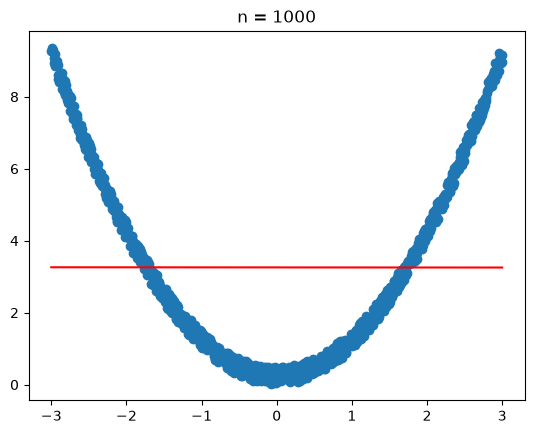

In [10]:
plt.scatter(x,y)
plt.plot(x,y_pred,color='red')
plt.title(f'n = {n}')
plt.show()

# DEEP Apply

In [11]:
data = pd.read_csv("files/Churn_Modelling.csv")

In [12]:
data.sample(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
1350,1351,15613141,Hsu,717,France,Female,41,3,135756.96,1,1,1,103706.41,0
7292,7293,15768474,Clements,744,Spain,Male,34,3,0.00,2,1,0,27244.35,0
7695,7696,15629985,Eidson,723,Germany,Female,47,10,90450.00,2,0,0,103379.31,1
34,35,15732963,Clements,722,Spain,Female,29,9,0.00,2,1,1,142033.07,0
6624,6625,15811036,Ferri,565,France,Male,46,7,135369.71,1,0,1,140130.22,0
534,535,15567832,Shih,550,France,Female,40,7,114354.95,1,1,0,54018.93,0
9430,9431,15591980,Hill,753,France,Male,33,5,122568.05,2,1,1,82820.85,0
1427,1428,15799966,Chigolum,792,Germany,Female,59,9,101609.77,1,0,0,161479.19,1
6182,6183,15723786,Morris,709,France,Female,37,9,0.00,2,1,0,16733.59,0
6979,6980,15751180,Adams,539,France,Female,40,7,81132.21,1,1,0,167289.82,0


In [13]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [15]:
data.duplicated().sum()

np.int64(0)

In [17]:
data.drop(['RowNumber','CustomerId','Surname'],axis=1, inplace=True)

In [18]:
data.sample(10)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9184,695,Spain,Female,56,4,0.00,2,1,0,84644.76,0
1564,773,Germany,Female,42,8,152324.66,2,1,0,171733.22,0
5802,499,France,Male,35,10,0.00,2,1,0,10722.54,0
5490,655,Spain,Female,78,2,0.00,2,0,1,188435.38,0
2173,698,France,Female,46,0,0.00,2,1,1,125962.02,0
4387,732,Spain,Female,67,1,0.00,2,1,1,177783.04,0
6245,591,Spain,Male,39,8,0.00,2,0,0,42392.24,0
1265,534,France,Female,55,8,116973.26,3,1,0,122066.50,1
3259,841,France,Male,31,2,0.00,2,1,0,173240.52,0
5472,457,Germany,Male,42,4,126772.57,1,0,1,126106.40,0


In [21]:
data = pd.get_dummies(data, columns=['Geography','Gender'], drop_first=True)

In [43]:
data

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [44]:
x = data.drop('Exited',axis=1)
y = data['Exited']

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

# standardization

In [53]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model of DL

In [54]:
model = Sequential()

# define inputs
model.add(Input(shape=(11,)))

# define hidden layer: 3 neuron
model.add(Dense(3, activation='sigmoid'))

# define output layer
model.add(Dense(1, activation='sigmoid'))

In [55]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

# optimiser

In [56]:
model.compile(loss='binary_crossentropy', optimizer='adam')

In [62]:
model.fit(X_train_scaled, y_train, epochs=50)

Epoch 1/50


250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4112
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4108
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4105
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4101
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4098
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4096
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4093
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4091
Epoch 9/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4088
Epoch 10/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4086
Epoch 11/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4084
Epoch 12/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4083
Epoch 13/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4080
Epoch 14/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4079
Epoch 15/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4077


In [63]:
# prediction

In [64]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [65]:
y_pred = np.where(y_log > 0.5, 1,0)
y_pred

array([[0],
       [0],
       [0],
       ...,
       [1],
       [0],
       [0]], shape=(2000, 1))

In [66]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8425